# 05 · Feature Engineering

Window-level features (30 s, 15-s step) were computed per signal in `src/signals/processing.py`, each with its own
processing, and masked by the quality rules of notebook 02. This notebook documents them, checks their redundancy,
and measures how much each one, **on its own**, separates the three physiological states. All of this happens before
any model is trained.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.visualization import plots as P

P.set_style()
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
PROCESSED = ROOT / "data" / "processed"; INTERIM = ROOT / "data" / "interim"
C = P.COND_COLORS

from src.signals.quality import masked_features
from src.models.classify import FEATURE_SETS, FEATURE_LABELS
from src.models.stats import paired_effect

w = pd.read_csv(PROCESSED / "windows.csv")
m = masked_features(w)
FEATURES = FEATURE_SETS["All signals"]

## 1 · Feature dictionary

| Signal | Feature | Definition | Physiological meaning |
|---|---|---|---|
| ACC | `acc_movement` | mean of the 1-s rolling SD of \|ACC\| (g) | movement intensity (dynamic component) |
| ACC | `acc_enmo` | mean of max(\|ACC\| − 1 g, 0) | accelerations beyond gravity |
| ACC | `acc_dom_freq_per_min` | dominant frequency of \|ACC\| in 0.7–4 Hz | movement rhythm (≈ 2 × cadence) |
| ACC | `acc_periodicity` | spectral concentration at that frequency | rhythmic vs irregular movement |
| HR | `hr_mean`, `hr_max` | Empatica HR in the window (quality-valid only) | cardiovascular load / sympathovagal balance |
| HR | `hr_slope` | linear trend (bpm/min) | HR kinetics: on-response or recovery |
| EDA | `eda_tonic_mean` | 0.05-Hz low-pass of cleaned EDA (µS) | skin-conductance level: sympathetic sudomotor tone, sweating |
| EDA | `eda_tonic_slope` | trend of the tonic level (µS/min) | rising or falling arousal or sweating |
| EDA | `eda_clean_sd` | SD of cleaned EDA | overall electrodermal variability |
| EDA | `eda_scr_rate` | SCRs per minute (rise ≥ max(0.05 µS, 2% of tonic)) | phasic sympathetic bursts |
| EDA | `eda_scr_amp` | mean SCR amplitude (µS) | burst size |
| TEMP | `temp_mean` | mean skin temperature (°C), fault codes masked | peripheral perfusion / thermal state |
| TEMP | `temp_slope` | trend (°C/min) | vasoconstriction (↓) or heat dissipation (↑) |

HRV (RMSSD, SDNN) is **not** a window feature: it needs long, clean beat series and is only valid in the seated stress
protocol (notebook 02). It is analysed at segment level in notebook 06.

## 2 · Classification target

| Class | Windows | Rationale |
|---|---|---|
| `STRESS` | stress tasks (TMCT, Stroop, opinion, opposite opinion, subtraction) | acute psychological stress while seated |
| `AEROBIC` | all aerobic stages (60–110 rpm) | sustained submaximal-to-maximal cycling |
| `ANAEROBIC` | sprints **plus the first 2 min of the following cooldown** | the all-out bout *and* its physiological aftermath: the HR and EDA responses lag the mechanical effort (notebook 04) |

Defining `ANAEROBIC` as the sprint alone would make it a pure movement-detection problem (30 s of maximal pedalling),
and HR is unmeasurable during sprints. Including the immediate recovery describes the *physiological state* the brief
asks about.

In [2]:
def target(r):
    if r.state == "STRESS_TASK":
        return "STRESS"
    if r.state == "AEROBIC_STAGE" and r.session_id != "S11_b":
        return "AEROBIC"
    if r.analysis_state in ("SPRINT", "POST_SPRINT"):
        return "ANAEROBIC"
    return None

m["target"] = [target(r) for r in m.itertuples()]
cls = m[m.target.notna()].copy()
keep = ["condition", "session_id", "subject_id", "cohort", "segment", "state", "analysis_state", "start_s", "end_s", "target"] + FEATURES
cls[keep].to_csv(PROCESSED / "classification_windows.csv", index=False)
summary = cls.groupby("target").agg(windows=("subject_id", "size"), participants=("subject_id", "nunique"))
summary["windows_per_participant"] = (summary.windows / summary.participants).round(1)
summary

,windows,participants,windows_per_participant
target,,,
AEROBIC,2401,30,80.000
ANAEROBIC,849,31,27.400
STRESS,668,36,18.600


In [3]:
miss = cls.groupby("target")[FEATURES].apply(lambda d: d.isna().mean()).T
miss.index = [FEATURE_LABELS[f] for f in miss.index]
print("Share of windows with the feature missing (invalid signal) per class")
miss.round(2)

Share of windows with the feature missing (invalid signal) per class


target,AEROBIC,ANAEROBIC,STRESS
Movement intensity (SD |ACC|),0.000,0.040,0.000
ACC ENMO,0.000,0.040,0.000
Movement rhythm (per min),0.000,0.040,0.000
Movement periodicity,0.000,0.040,0.000
HR mean,0.570,0.890,0.430
HR max,0.570,0.890,0.430
HR slope,0.570,0.890,0.430
EDA tonic level,0.020,0.030,0.010
EDA tonic slope,0.020,0.030,0.010
EDA variability,0.020,0.030,0.010


Missingness is **informative and class-dependent**: HR is missing in most `ANAEROBIC` windows because the PPG fails
during and right after sprints. A model could learn "HR missing → anaerobic", which is a property of the sensor, not of
physiology. Mitigation in notebook 07: models see median-imputed values plus explicit missing-indicator columns, and the
ablation shows how much each modality contributes. That lets a missingness shortcut be recognised rather than
mistaken for physiology.

## 3 · Distributions by class (participant means)

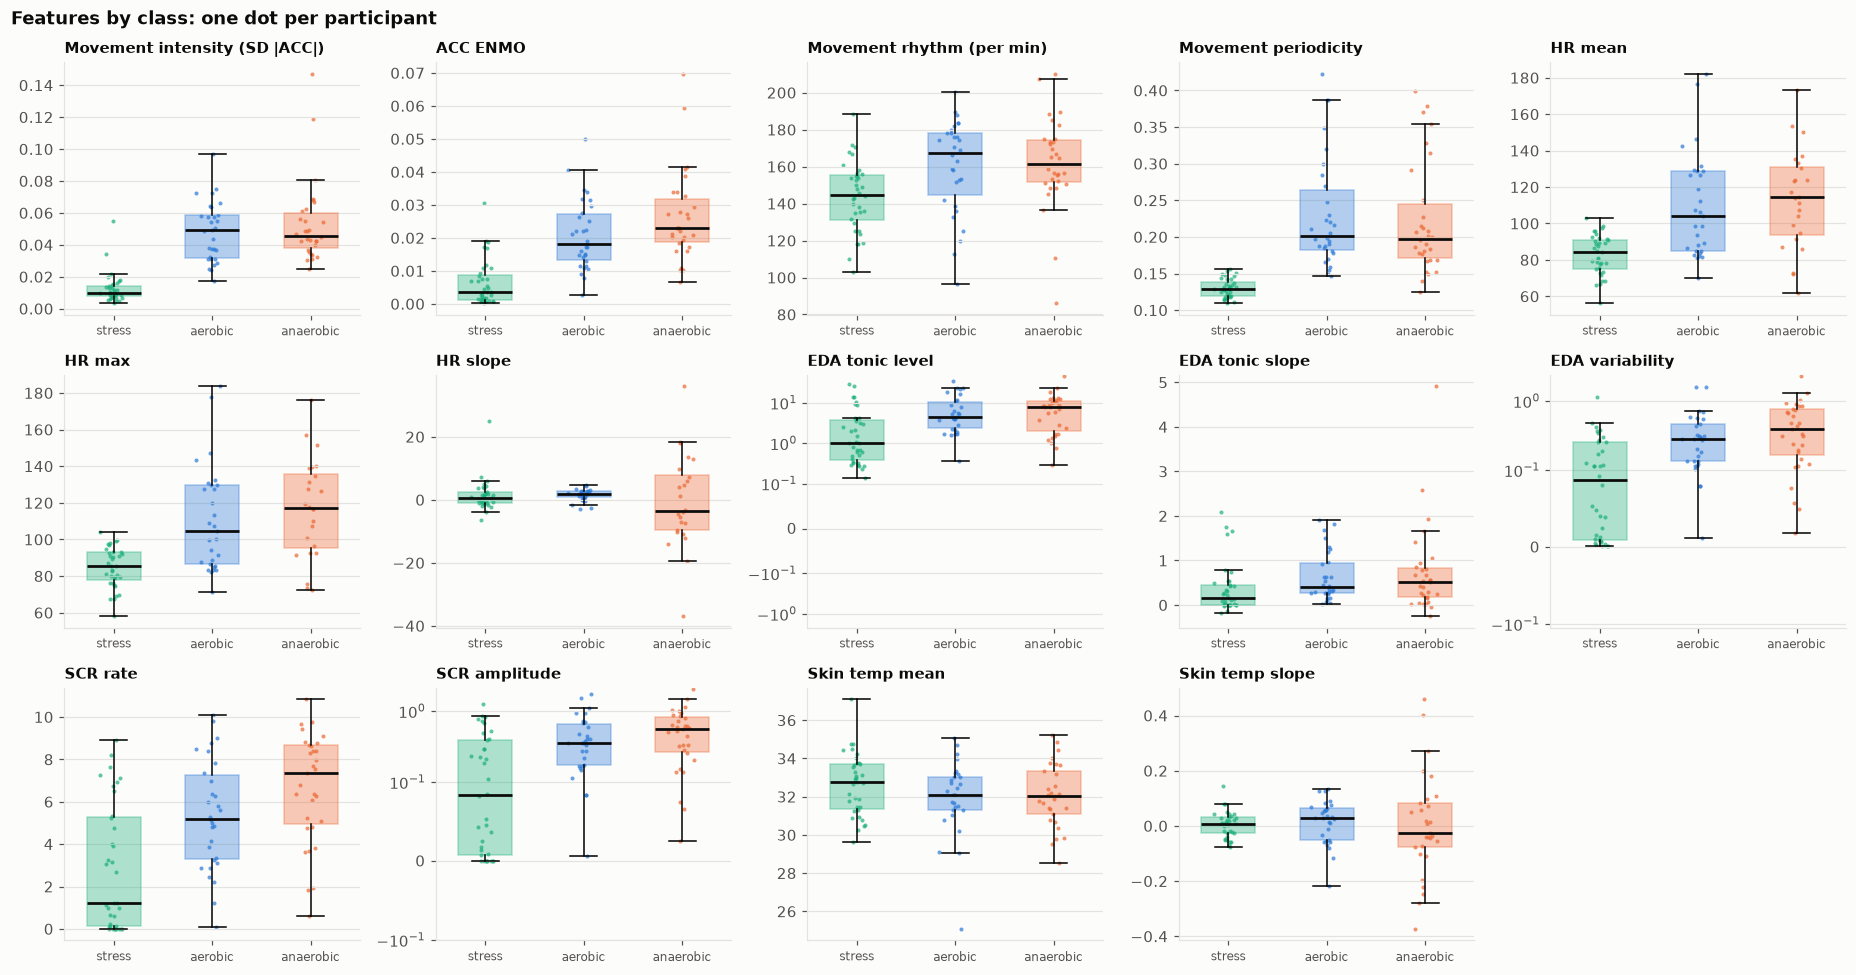

In [4]:
pmc = cls.groupby(["subject_id", "target"])[FEATURES].mean().reset_index()
order = ["STRESS", "AEROBIC", "ANAEROBIC"]
fig, axes = plt.subplots(3, 5, figsize=(17, 9))
for ax, f in zip(axes.flat, FEATURES):
    data = [pmc[pmc.target == c][f].dropna() for c in order]
    bp = ax.boxplot(data, widths=0.55, showfliers=False, patch_artist=True, medianprops=dict(color=P.TEXT, lw=1.8))
    for patch, c in zip(bp["boxes"], order):
        patch.set_facecolor(C[c]); patch.set_alpha(0.35); patch.set_edgecolor(C[c])
    for i, d in enumerate(data):
        ax.scatter(np.random.default_rng(i).normal(i + 1, 0.06, len(d)), d, s=7, color=C[order[i]], alpha=0.7, lw=0)
    ax.set_xticks([1, 2, 3], ["stress", "aerobic", "anaerobic"], fontsize=8)
    ax.set_title(FEATURE_LABELS[f], loc="left", fontsize=9.5); ax.grid(axis="x", visible=False)
    if f in ("eda_tonic_mean", "eda_clean_sd", "eda_scr_amp"):
        ax.set_yscale("symlog", linthresh=0.1)
for ax in axes.flat[len(FEATURES):]: ax.axis("off")
fig.suptitle("Features by class: one dot per participant", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); P.save(fig, "05_feature_distributions"); plt.show()

## 4 · Univariate discrimination at the participant level

For each feature and pair of classes, a **paired Cohen's d_z** across participants who have both classes, with a
bootstrap 95% CI. This answers "which single signal carries information?" without any model and without
pseudo-replicating windows.

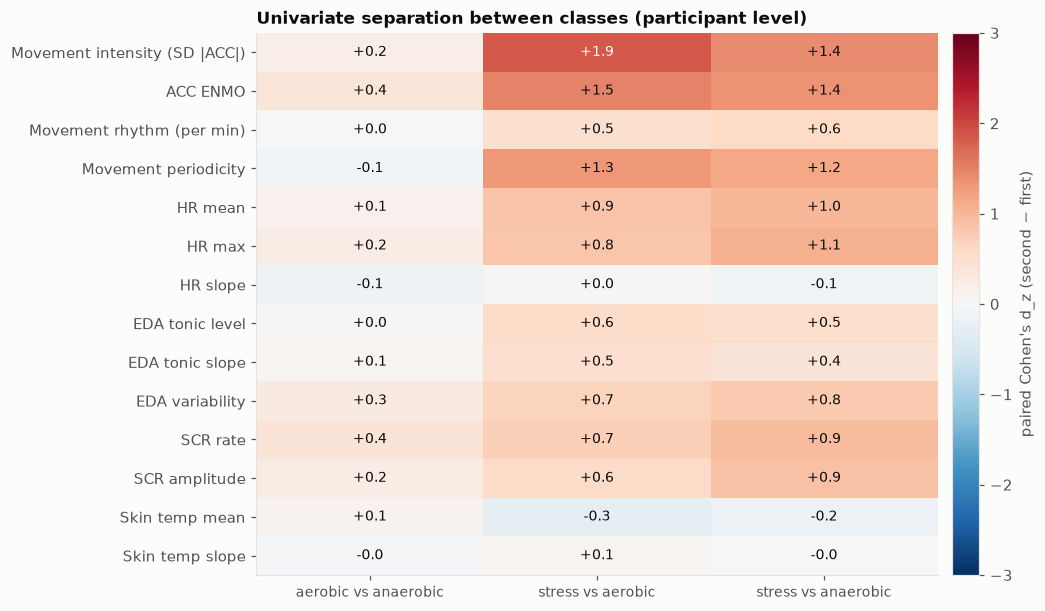

,feature,pair,n,mean_diff,dz,dz_low,dz_high
0,acc_movement,stress vs aerobic,30,0.040,1.850,1.550,2.380
3,acc_enmo,stress vs aerobic,30,0.010,1.490,1.180,2.030
1,acc_movement,stress vs anaerobic,30,0.040,1.420,1.110,2.590
4,acc_enmo,stress vs anaerobic,30,0.020,1.350,1.030,2.230
9,acc_periodicity,stress vs aerobic,30,0.100,1.290,1.070,1.680
10,acc_periodicity,stress vs anaerobic,30,0.090,1.160,0.970,1.460
16,hr_max,stress vs anaerobic,24,32.040,1.080,0.670,1.780
13,hr_mean,stress vs anaerobic,24,30.260,1.000,0.600,1.690
31,eda_scr_rate,stress vs anaerobic,31,3.730,0.950,0.560,1.540
34,eda_scr_amp,stress vs anaerobic,31,0.340,0.870,0.630,1.230


In [5]:
pairs = [("STRESS", "AEROBIC"), ("STRESS", "ANAEROBIC"), ("AEROBIC", "ANAEROBIC")]
rows = []
for f in FEATURES:
    wide = pmc.pivot(index="subject_id", columns="target", values=f)
    for a, b in pairs:
        d = wide[[a, b]].dropna()
        e = paired_effect(d[a].to_numpy(), d[b].to_numpy())
        rows.append(dict(feature=f, pair=f"{a.lower()} vs {b.lower()}", **e))
uni = pd.DataFrame(rows)
uni.to_csv(PROCESSED / "univariate_effects.csv", index=False)
heat = uni.pivot(index="feature", columns="pair", values="dz").reindex(FEATURES)
fig, ax = plt.subplots(figsize=(8.5, 6.4))
im = ax.imshow(heat.to_numpy(), cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.iloc[i, j]
        ax.text(j, i, "–" if not np.isfinite(v) else f"{v:+.1f}", ha="center", va="center", fontsize=9,
                color="white" if np.isfinite(v) and abs(v) > 1.8 else P.TEXT)
ax.set_xticks(range(heat.shape[1]), heat.columns, fontsize=9); ax.set_yticks(range(len(FEATURES)), [FEATURE_LABELS[f] for f in FEATURES])
ax.grid(False); cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cb.set_label("paired Cohen's d_z (second − first)")
ax.set_title("Univariate separation between classes (participant level)", loc="left")
P.save(fig, "05_univariate_effects"); plt.show()
uni.assign(abs_dz=uni.dz.abs()).sort_values("abs_dz", ascending=False).head(12)[["feature", "pair", "n", "mean_diff", "dz", "dz_low", "dz_high"]].round(2)

How to read it: |d_z| ≥ 0.8 is a large within-person difference.
- **Stress vs exercise:** movement features dominate (d_z 1.2–1.9). That is expected and physiologically trivial:
  seated people do not pedal. HR also separates stress from both exercise types with large effects (aerobic
  d_z ≈ 0.86, anaerobic ≈ 1.0, about +24–30 bpm), and so do SCR rate and EDA level (d_z ≈ 0.5–0.95).
- **Aerobic vs anaerobic:** **no single feature separates them well** at the participant level. The largest effects
  are small (SCR rate d_z ≈ 0.38, ENMO ≈ 0.36, with CIs reaching near zero). Averaged over a session, the two kinds
  of cycling have similar HR, EDA and temperature. What differs is the *time course within the session* (bursts and
  recoveries vs steady progression), which participant means wash out. Notebook 07 tests whether window-level
  combinations of features can recover it.
- **Skin temperature** separates nothing reliably.

## 5 · Redundancy between features

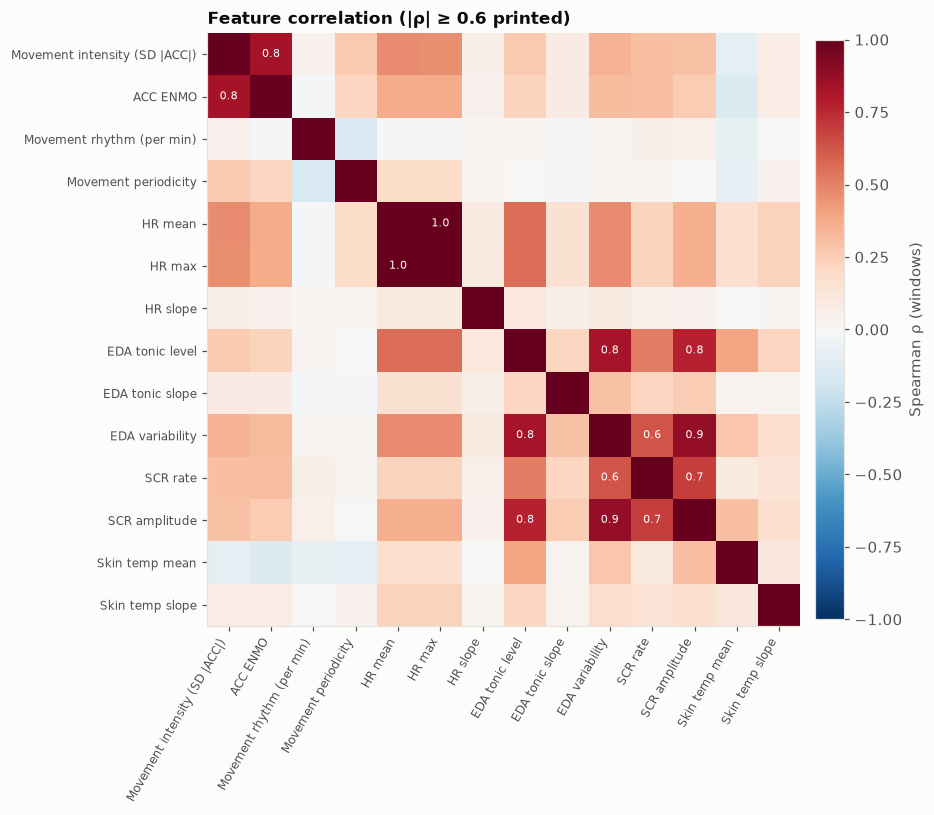

Pairs with |rho| >= 0.7:
hr_mean         hr_max         1.000
eda_clean_sd    eda_scr_amp    0.880
acc_movement    acc_enmo       0.830
eda_tonic_mean  eda_clean_sd   0.830
                eda_scr_amp    0.770


In [6]:
corr = cls[FEATURES].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), [FEATURE_LABELS[f] for f in FEATURES], rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(FEATURES)), [FEATURE_LABELS[f] for f in FEATURES], fontsize=8)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        if i != j and abs(corr.iloc[i, j]) >= 0.6:
            ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7, color="white")
ax.grid(False); fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02).set_label("Spearman ρ (windows)")
ax.set_title("Feature correlation (|ρ| ≥ 0.6 printed)", loc="left")
P.save(fig, "05_feature_correlation"); plt.show()
high = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().loc[lambda s: s.abs() >= 0.7].sort_values(key=abs, ascending=False)
print("Pairs with |rho| >= 0.7:"); print(high.round(2).to_string())

Some features are strongly redundant within modality (HR mean/max; movement intensity/ENMO; EDA tonic level and
variability). No features are dropped. The models in notebook 07 are compared with permutation importance, which
**splits credit between correlated features**. Importance is therefore interpreted at the level of the modality,
not the individual feature.